# Lesson 4.3: The Central Limit Theorem

Show that sample means from a very skewed population become more symmetric and bell-shaped as the sample size grows from 1 to 5 to 30.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. A skewed population

Waiting times in a clinic: exponential, with a mean of 10 minutes and an SD of 10. Lots of short waits and a long tail of rare long ones, so it is clearly skewed to the right.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(99)

def sample_means(n, reps=5000):
    return rng.exponential(10, size=(reps, n)).mean(axis=1)

single = rng.exponential(10, size=5000)
print(f'skewness of single waits = {stats.skew(single):.2f}')

skewness of single waits = 1.89


## 2. Skewness of the sample means

Skewness is 0 for a perfectly symmetric shape. For each n we take 5,000 sample means and measure their skewness. It falls towards 0 roughly like 2 divided by the square root of n.

In [2]:
print('  n   skewness of means   2/sqrt(n)')
for n in (1, 5, 30):
    m = sample_means(n)
    print(f'{n:3d}   {stats.skew(m):15.2f}   {2 / np.sqrt(n):9.2f}')

  n   skewness of means   2/sqrt(n)
  1              1.93        2.00
  5              0.85        0.89
 30              0.33        0.37


## 3. Three histograms

The same story as a picture. With n = 1 we see the skewed population itself. With n = 5 the shape is already more balanced, and with n = 30 it looks close to a bell.

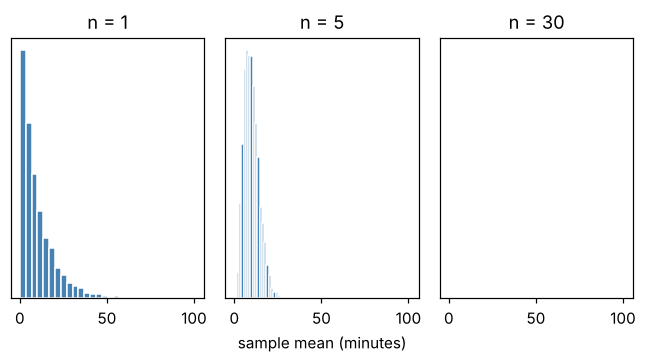

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(6, 3.4), sharex=True)
for ax, n in zip(axes, (1, 5, 30)):
    ax.hist(sample_means(n), bins=30, color='steelblue', edgecolor='white')
    ax.set_title(f'n = {n}')
    ax.set_yticks([])
axes[1].set_xlabel('sample mean (minutes)')
plt.tight_layout()
plt.show()

## 4. Use the bell curve

The lesson's clinic question: for n = 40 patients, how often does the mean wait reach 12 minutes or more? The CLT lets us use a normal curve with mean 10 and SE = 10 divided by the square root of 40.

In [4]:
se = 10 / np.sqrt(40)
p_clt = stats.norm.sf(12, loc=10, scale=se)
simulated = (sample_means(40, reps=20000) >= 12).mean()

print(f'SE = {se:.3f}')
print(f'CLT answer       P(mean >= 12) = {p_clt:.3f}')
print(f'simulation (20k) P(mean >= 12) = {simulated:.3f}')

SE = 1.581
CLT answer       P(mean >= 12) = 0.103
simulation (20k) P(mean >= 12) = 0.110


## Try this

- Add n = 100 to the loop and predict whether the skewness will be above or below 0.2.
- Make the population even more skewed with rng.lognormal(0, 1.2, ...) in place of the exponential. How big must n be before the means look symmetric?
- Change the clinic cut-off from 12 to 11 minutes and predict the new probability.

## The same idea in R, SPSS and Stata

**R**

```r
skew <- function(x) mean((x - mean(x))^3) / mean((x - mean(x))^2)^1.5
set.seed(99)
for (n in c(1, 5, 30)) print(skew(replicate(5000, mean(rexp(n, rate = 1/10)))))
pnorm(12, mean = 10, sd = 10 / sqrt(40), lower.tail = FALSE)
```

**SPSS** (Analyze > Descriptive Statistics > Descriptives > Options > Skewness)

```
SET SEED=99.
INPUT PROGRAM.
LOOP s = 1 TO 5000.
COMPUTE x1 = RV.EXP(1/10).
COMPUTE total = 0.
LOOP i = 1 TO 30.
COMPUTE total = total + RV.EXP(1/10).
END LOOP.
COMPUTE mean30 = total/30.
END CASE.
END LOOP.
END FILE.
END INPUT PROGRAM.
DESCRIPTIVES VARIABLES=x1 mean30 /STATISTICS=MEAN STDDEV SKEWNESS.
```

**Stata**

```
clear
set seed 99
set obs 5000
generate x1 = rexponential(10)
generate mean30 = 0
forvalues i = 1/30 {
    quietly replace mean30 = mean30 + rexponential(10) / 30
}
tabstat x1 mean30, statistics(mean sd skewness)
display 1 - normal((12 - 10) / (10 / sqrt(40)))
```